# 02 · Overlays and calculations: what is near what, who can reach what, where things cluster

Every spatial question is built from a few operations. This notebook does each one on Quetta's data from
notebook 01, with the question it answers.

| Operation | Question it answers |
|---|---|
| buffer | what lies within 500 m of a school? |
| spatial join, point in polygon | how many clinics are in each part of the city? |
| grid aggregation | where are buildings and people densest? |
| raster to zones (zonal statistics) | how many people live in each cell or area? |
| network distance, isochrones | who can walk to a clinic in 15 minutes? |
| nearest neighbour | how far is each home from the nearest school? |
| kernel density | where do shops concentrate? |
| spatial autocorrelation, hot spots | is that clustering more than chance? |

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, osmnx as ox, networkx as nx
import matplotlib.pyplot as plt, rasterio
from rasterio.features import geometry_mask
from shapely.geometry import box
DATA, CRS = Path("data"), 32642
area = gpd.read_file(DATA / "boundary.gpkg").to_crs(CRS)
bld = gpd.read_file(DATA / "buildings_overture.gpkg").to_crs(CRS)
poi = gpd.read_file(DATA / "places.gpkg").to_crs(CRS)
G = ox.load_graphml(DATA / "walk.graphml")
print(len(bld), "buildings,", len(poi), "places")

254056 buildings, 1641 places


## 1. A grid to compare like with like
Administrative areas differ in size and shape; a regular grid of 500 m cells makes counts comparable.

In [2]:
S = 500
x0, y0, x1, y1 = area.total_bounds
cells = [box(x, y, x + S, y + S) for x in np.arange(x0, x1, S) for y in np.arange(y0, y1, S)]
grid = gpd.GeoDataFrame(geometry=cells, crs=CRS)
grid = grid[grid.intersects(area.geometry.iloc[0])].reset_index(drop=True); grid["cell"] = grid.index
print(len(grid), "cells of 500 m")

1890 cells of 500 m


## 2. Spatial join: buildings and built-up area per cell

In [3]:
b = bld[["geometry"]].copy(); b["footprint_m2"] = b.area
b["geometry"] = b.representative_point()
j = gpd.sjoin(b, grid, predicate="within").groupby("cell").agg(buildings=("footprint_m2", "size"), built_m2=("footprint_m2", "sum"))
grid = grid.join(j).fillna({"buildings": 0, "built_m2": 0})
grid["built_share"] = grid.built_m2 / S**2
grid.describe().loc[["mean", "50%", "max"], ["buildings", "built_share"]].round(3)

,buildings,built_share
mean,134.421,0.065
50%,1.500,0.000
max,1174.000,0.696


## 3. Zonal statistics: people per cell from the population raster

people in grid: 646,850


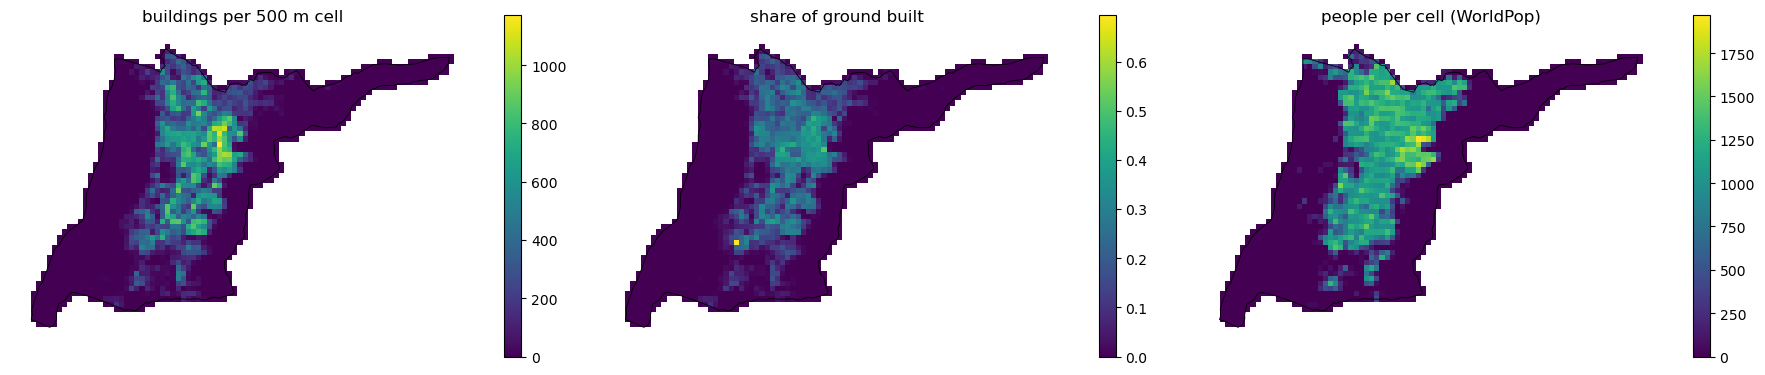

In [4]:
with rasterio.open(DATA / "population.tif") as src:
    pop = src.read(1, masked=True).filled(0); tr, pcrs = src.transform, src.crs
g4 = grid.to_crs(pcrs)
grid["people"] = [pop[~geometry_mask([geom], pop.shape, tr, all_touched=False)].sum() for geom in g4.geometry]
grid["people_per_building"] = grid.people / grid.buildings.replace(0, np.nan)
print(f"people in grid: {grid.people.sum():,.0f}")
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (col, t) in zip(ax, [("buildings", "buildings per 500 m cell"), ("built_share", "share of ground built"), ("people", "people per cell (WorldPop)")]):
    grid.plot(col, ax=a, cmap="viridis", legend=True, legend_kwds={"shrink": .6}); area.boundary.plot(ax=a, color="k", lw=.6); a.set_title(t); a.set_axis_off()
plt.tight_layout()

## 4. Buffers: what is within 500 m of a school?

In [5]:
schools = poi[poi.category == "education"]
reach = schools.buffer(500).union_all()
grid_pts = grid.copy(); grid_pts["geometry"] = grid.centroid
covered = grid_pts.within(reach)
print(f"{len(schools)} schools; people in cells whose centre is within 500 m of one: {grid.people[covered].sum() / grid.people.sum():.0%}")

306 schools; people in cells whose centre is within 500 m of one: 43%


A buffer is a straight-line circle. People walk along streets, around walls and across few bridges, so the next
step uses the street network instead.

## 5. Network distance: who can walk to a clinic in 15 minutes?
Each street segment gets a walking time (4.5 km/h). From every clinic we grow the area reachable in 15 minutes
(an *isochrone*) by a shortest-path search on the graph.

In [6]:
SPEED = 4.5 * 1000 / 60                                  # metres per minute
for u, v, k, d in G.edges(keys=True, data=True):
    d["minutes"] = d["length"] / SPEED
health = poi[poi.category == "health"].to_crs(4326)
src_nodes = set(ox.distance.nearest_nodes(G, health.geometry.x, health.geometry.y)) if len(health) else set()
t = nx.multi_source_dijkstra_path_length(G, src_nodes, weight="minutes") if src_nodes else {}
nodes = ox.graph_to_gdfs(G, edges=False).to_crs(CRS)
nodes["min_to_clinic"] = nodes.index.map(t)
grid_nn = gpd.sjoin_nearest(grid_pts[["cell", "geometry"]], nodes[["min_to_clinic", "geometry"]], how="left").drop_duplicates("cell").set_index("cell")
grid["min_to_clinic"] = grid_nn.min_to_clinic.reindex(grid.cell).values
for m_ in (5, 10, 15, 30):
    print(f"people within {m_:2} min walk of a clinic or pharmacy: {grid.people[grid.min_to_clinic <= m_].sum() / grid.people.sum():.0%}")

people within  5 min walk of a clinic or pharmacy: 11%
people within 10 min walk of a clinic or pharmacy: 25%
people within 15 min walk of a clinic or pharmacy: 38%
people within 30 min walk of a clinic or pharmacy: 71%


**Reading:** on these data, about 38% of people live within a 15-minute walk of a mapped clinic or pharmacy, and
71% within 30 minutes. Only about 155 health places are mapped for a city of over a million, so the true figures
are higher: this measures *mapped* access, and the gap between the two is a finding in itself.

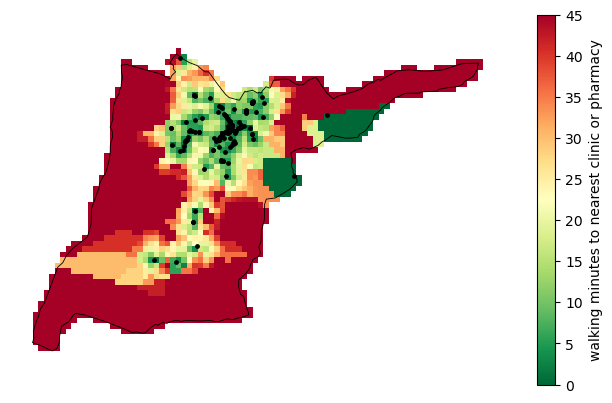

In [7]:
ax = grid.plot("min_to_clinic", cmap="RdYlGn_r", vmax=45, legend=True, figsize=(8, 8), legend_kwds={"label": "walking minutes to nearest clinic or pharmacy", "shrink": .6})
health.to_crs(CRS).plot(ax=ax, color="black", markersize=6); area.boundary.plot(ax=ax, color="k", lw=.6); ax.set_axis_off();

## 6. Kernel density: where do shops concentrate?
Kernel density smooths points into a surface: each shop spreads a little bump of 300 m; bumps add up.

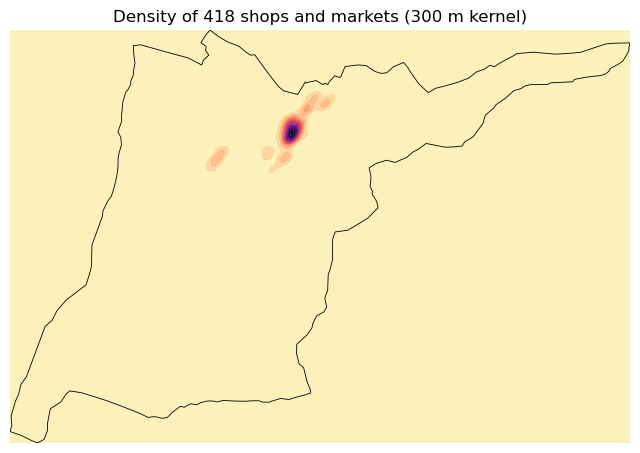

In [8]:
from scipy.stats import gaussian_kde
shops = poi[poi.category == "shops and markets"]
xy = np.vstack([shops.geometry.x, shops.geometry.y])
kde = gaussian_kde(xy, bw_method=300 / xy.std(axis=1).mean())
gx, gy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
z = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(8, 8))
ax.contourf(gx, gy, z, levels=15, cmap="magma_r", alpha=.85); area.boundary.plot(ax=ax, color="k", lw=.6)
ax.set_title(f"Density of {len(shops)} shops and markets (300 m kernel)"); ax.set_axis_off();

## 7. Is it clustered more than chance? Moran's I and hot spots
*Moran's I* asks whether neighbouring cells have similar values (I > 0: clustering). *Getis-Ord Gi\** marks cells
whose neighbourhood is much higher (hot) or lower (cold) than the city overall.

Moran's I = 0.45, pseudo p = 0.001


hotspot
not significant    1870
hot                  20
Name: count, dtype: int64

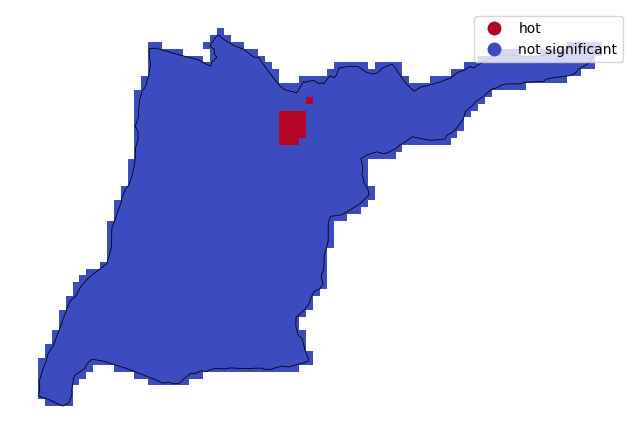

In [9]:
from libpysal.weights import Queen
from esda.moran import Moran
from esda.getisord import G_Local
grid["shops"] = gpd.sjoin(shops[["geometry"]], grid, predicate="within").groupby("cell").size().reindex(grid.cell).fillna(0).values
w = Queen.from_dataframe(grid, use_index=False); w.transform = "r"
mi = Moran(grid.shops.values, w, permutations=999)
print(f"Moran's I = {mi.I:.2f}, pseudo p = {mi.p_sim:.3f}")
gl = G_Local(grid.shops.values.astype(float), w, star=True, permutations=999, seed=0)
grid["hotspot"] = np.select([(gl.Zs > 1.96) & (gl.p_sim < .05), (gl.Zs < -1.96) & (gl.p_sim < .05)], ["hot", "cold"], "not significant")
ax = grid.plot("hotspot", categorical=True, cmap="coolwarm_r", legend=True, figsize=(8, 8)); area.boundary.plot(ax=ax, color="k", lw=.6); ax.set_axis_off()
grid.hotspot.value_counts()

## 8. Save the results for maps and questions

In [10]:
grid.to_file(DATA / "grid_500m.gpkg")
grid[["buildings", "built_share", "people", "min_to_clinic", "shops"]].describe().round(2)

,buildings,built_share,people,min_to_clinic,shops
count,1890.00,1890.00,1890.00,1890.00,1890.00
mean,134.42,0.07,342.25,58.43,0.22
std,228.42,0.11,511.32,40.62,1.89
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,24.28,0.00
50%,1.50,0.00,0.00,52.99,0.00
75%,192.75,0.10,797.70,96.18,0.00
max,1174.00,0.70,1973.04,185.40,46.00


## Caveats to state in any write-up
- Results depend on the grid (try 250 m and 1 km): the *modifiable areal unit problem*.
- Missing OSM data look like poor access. Check tags, coverage and local knowledge before claiming a gap.
- Walking times ignore slope, safety, gates, traffic and who is allowed where. Notebook 04 shows how to bring
  these in for particular groups.